# 03. 近傍保持レイアウト（Track A / Track B / 統一近傍ソルバ）

このノートブックでは、2-hop 近傍保持率（NP2）や局所クラスタ構造の再現に優れた `egraph` v6 の近傍保持レイアウト群と、それを支える 26 種類の近傍・パープレキシティ・DoG / rHGH プリミティブを網羅します。

- **Track A (`TsNetSolver`)**: FFT 補間 (`"fft"`, `"linear_fft"`) / Barnes-Hut (`"barnes_hut"`) / 厳密計算 (`"exact"`) を備えた高速 tsNET ソルバ
- **Track B (`SgdSolver.sparse_barrier_*` / `GuMapSolver`)**: DoG Varadhan ランドマークおよび 3 層スパースバリア SGD / GuMap ソルバ
- **統一近傍・力場ソルバ**: `TFdpSolver`, `IbUmapSolver`, `SgdSolver.{snap_t_fdp, pacmap_graph*, largevis, drgraph, graph_cne}`
- **近傍・確率・スペクトルランドマーク構築プリミティブ**: 全 26 種

In [ ]:
!pip install -q --pre "egraph==6.0.0a8" matplotlib-fontja

## 1. インポートと前提条件（連結成分抽出・2-hop 近傍統計・パープレキシティ）

非連結グラフでは距離・確率の正規化や近傍推定の品質が低下しやすいため、`poli` のように非連結なグラフでは事前に `largest_connected_component()` で最大連結成分を抽出するのが推奨されます。
ここでは、1-hop / 2-hop CSR 抽出や適応的パープレキシティ計算プリミティブも確認します。

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg


def plot_graph_2d(graph: eg.CsrGraph, layout: eg.Layout2d, ax, title: str = "", node_size: float = 10.0):
    """Plot 2D graph layout strictly with matplotlib LineCollection + scatter."""
    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segments = [
        [coords[u], coords[int(v)]]
        for u in range(graph.num_nodes)
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]
        if graph.is_directed or u < int(v)
    ]
    if segments:
        ax.add_collection(LineCollection(segments, colors="#777777", linewidths=0.45, alpha=0.22, zorder=1))
    ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c="#1f77b4", edgecolors="white", linewidths=0.2, zorder=2)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)


g_poli = eg.load_dataset("poli")
g_poli_lcc, _ = g_poli.largest_connected_component()
print(f"poli LCC check: {g_poli.num_nodes} -> {g_poli_lcc.num_nodes} nodes")

g_qh = eg.load_dataset("qh882")
g_dwt = eg.load_dataset("dwt_1005")
g_3elt = eg.load_dataset("3_elt")

# 2-hop neighborhood extraction and adaptive perplexity primitives
g1, g2 = eg.extract_1hop_2hop_csr(g_qh)
pairs_12 = eg.extract_sparse_1hop_2hop_pairs(g_qh, max_2hop_per_node=32, seed=42)
sizes_2hop = eg.compute_2hop_neighborhood_sizes(g_qh)
perp_nodewise = eg.compute_nodewise_2hop_perplexities(g_qh, c=0.9, min_perplexity=5.0, max_perplexity=1200.0)
perp_median = eg.compute_median_2hop_perplexity(g_qh, c=1.5, min_perplexity=15.0, max_perplexity=1200.0)

print(
    f"extract_1hop_2hop_csr (qh882): 1-hop edges={g1.num_edges}, 2-hop edges={g2.num_edges}\n"
    f"Sparse12HopPairs: num_1hop={pairs_12.num_1hop}, num_2hop={pairs_12.num_2hop}, "
    f"len(u1)={len(pairs_12.u1())}, len(v2)={len(pairs_12.v2())}\n"
    f"2-hop sizes: min={sizes_2hop.min()}, median={np.median(sizes_2hop):.1f}, max={sizes_2hop.max()}\n"
    f"nodewise perplexities: [{perp_nodewise.min():.2f}, {perp_nodewise.max():.2f}], median_perp={perp_median:.2f}"
)

poli LCC check: 3915 -> 2343 nodes
extract_1hop_2hop_csr (qh882): 1-hop edges=1533, 2-hop edges=3548
Sparse12HopPairs: num_1hop=1533, num_2hop=3548, len(u1)=1533, len(v2)=3548
2-hop sizes: min=4, median=10.0, max=38
nodewise perplexities: [5.00, 34.20], median_perp=15.00


## 2. Track A: `TsNetSolver`（全 5 コンストラクタ・4 バックエンド・FFT 統計）

`TsNetSolver` は 3 ステージ最適化（`stage_index` 0 → 1 → 2）を行い、以下の 5 種類のコンストラクタと 4 種類のバックエンドを備えています。

- **5 コンストラクタ**: `pure_2hop`, `from_graph_row_normalized`, `from_knn`, `from_probabilities`, `from_graph_partial_bfs`
- **4 バックエンド**: `"exact"`, `"barnes_hut"`, `"fft"`, `"linear_fft"`  
  ※ `interpolation_order=1`（線形補間）がデフォルトであるため、`interpolation_order=1` のとき `"fft"` と `"linear_fft"` は同じ補間次数で動作します。3 次補間を使いたい場合は `backend="fft", interpolation_order=3` を指定します。

Backend             Time (ms)      NP2   FFT Calls Last FFT Stats
--------------------------------------------------------------------------------


exact                   901.6   0.6235           0 None


barnes_hut              589.1   0.6224           0 None


fft (order=1)          2176.2   0.6258        1600 {'particle_forward_ffts': 2, 'kernel_forward_ffts': 1, 'inverse_ffts': 2, 'total_fft_2d_calls': 5}


fft (order=3)          6270.0   0.6211        1600 {'particle_forward_ffts': 2, 'kernel_forward_ffts': 1, 'inverse_ffts': 2, 'total_fft_2d_calls': 5}


linear_fft             1679.0   0.6258        1600 {'particle_forward_ffts': 2, 'kernel_forward_ffts': 1, 'inverse_ffts': 2, 'total_fft_2d_calls': 5}



3_elt stage trace (total 3561.9 ms): [(1, 0, 1573.33), (100, 1, 1573.33), (101, 1, 1573.33), (200, 2, 1573.33), (201, 2, 1573.33), (400, 2, 1573.33)]
3_elt TsNet pure_2hop (100/100/200) NP2=0.7993
SparseProbabilities nnz: knn=10162, row1=3066, row12=10162, sym=3066


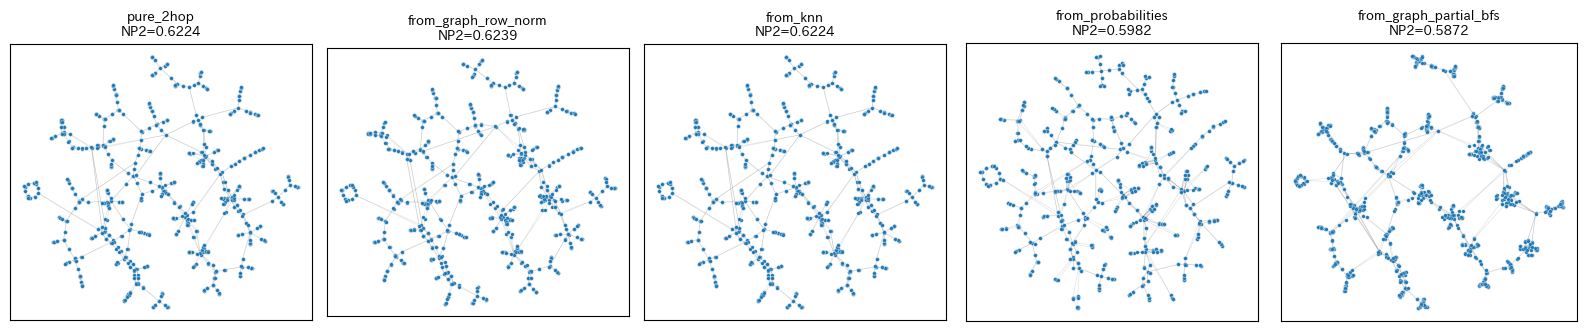

In [ ]:
# 1) Compare all 4 backends + interpolation_order=1 vs 3 on qh882 (reduced stage budget for speed)
stage_cfg = dict(iterations_stage1=80, iterations_stage2=80, iterations_stage3=160, seed=42)
backend_specs = [
    ("exact", dict(backend="exact")),
    ("barnes_hut", dict(backend="barnes_hut")),
    ("fft (order=1)", dict(backend="fft", interpolation_order=1)),
    ("fft (order=3)", dict(backend="fft", interpolation_order=3)),
    ("linear_fft", dict(backend="linear_fft")),
]

print(f"{'Backend':<18} {'Time (ms)':>10} {'NP2':>8} {'FFT Calls':>11} {'Last FFT Stats'}")
print("-" * 80)
for label, kw in backend_specs:
    lay = eg.pivot_mds_init(g_qh, num_pivots=50, seed=42)
    solver = eg.TsNetSolver.pure_2hop(g_qh, **kw, **stage_cfg)
    t0 = time.perf_counter()
    solver.run(lay)
    dt = (time.perf_counter() - t0) * 1000
    np2 = eg.neighborhood_preservation_2hop(g_qh, lay)
    print(f"{label:<18} {dt:>10.1f} {np2:>8.4f} {solver.total_fft_2d_calls:>11} {solver.last_fft_stats()}")

# 2) Track stage_index & current_stage_lr across stages on 3_elt (N=4720) with reduced stages (100,100,200)
lay_3elt = eg.pivot_mds_init(g_3elt, num_pivots=50, seed=42)
solver_3elt = eg.TsNetSolver.pure_2hop(
    g_3elt, backend="fft", iterations_stage1=100, iterations_stage2=100, iterations_stage3=200, seed=42
)
stage_trace = []
t0 = time.perf_counter()
for target_step in [1, 100, 101, 200, 201, 400]:
    solver_3elt.run_steps(lay_3elt, target_step - solver_3elt.iteration)
    stage_trace.append((solver_3elt.iteration, solver_3elt.stage_index, round(solver_3elt.current_stage_lr, 2)))
dt_3elt = (time.perf_counter() - t0) * 1000
print(f"\n3_elt stage trace (total {dt_3elt:.1f} ms):", stage_trace)
print(f"3_elt TsNet pure_2hop (100/100/200) NP2={eg.sampled_np2(g_3elt, lay_3elt):.4f}")

# 3) Demonstrate all 5 TsNetSolver constructors + probability primitives on qh882
knn_qh, _, _ = eg.build_pure_2hop_knn(g_qh)
probs_knn = eg.compute_knn_probabilities(knn_qh, perp_nodewise, power=2.0, row_normalize=False)
probs_row = eg.graph_row_normalized_probabilities(g_qh)
probs_12row = eg.graph_12hop_row_normalized_probabilities(g_qh, w2=0.5, max_2hop_per_node=32, seed=42)
probs_sym = eg.symmetrize_row_normalized(g_qh.num_nodes, probs_row.indptr(), probs_row.indices(), probs_row.values())
print(
    f"SparseProbabilities nnz: knn={probs_knn.nnz}, row1={probs_row.nnz}, "
    f"row12={probs_12row.nnz}, sym={probs_sym.nnz}"
)

tsnet_constructors = [
    ("pure_2hop", eg.TsNetSolver.pure_2hop(g_qh, backend="barnes_hut", **stage_cfg)),
    ("from_graph_row_norm", eg.TsNetSolver.from_graph_row_normalized(g_qh, w2=0.5, backend="barnes_hut", **stage_cfg)),
    ("from_knn", eg.TsNetSolver.from_knn(knn_qh, perplexities=perp_nodewise, backend="barnes_hut", **stage_cfg)),
    ("from_probabilities", eg.TsNetSolver.from_probabilities(probs_sym, backend="barnes_hut", **stage_cfg)),
    ("from_graph_partial_bfs", eg.TsNetSolver.from_graph_partial_bfs(g_qh, k=15, uniform_perplexity=15.0, backend="barnes_hut", **stage_cfg)),
]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, (name, solver) in zip(axes, tsnet_constructors):
    lay = eg.pivot_mds_init(g_qh, num_pivots=50, seed=42)
    solver.run(lay)
    np2 = eg.neighborhood_preservation_2hop(g_qh, lay)
    plot_graph_2d(g_qh, lay, ax=ax, title=f"{name}\nNP2={np2:.4f}", node_size=7)
plt.tight_layout()
plt.show()

## 3. スペクトルランドマーク（DoG Varadhan / rHGH）と `KnnGraph` 構築プリミティブ

Track B や統一ソルバで使う距離近似・近傍グラフ構築の 26 プリミティブのうち、ランドマーク・`KnnGraph`・UMAP ファジー単体集合・Horvitz-Thompson スケーリング・相対距離フロアを確認します。

In [ ]:
# 1) Regularized DoG Varadhan landmarks (from graph and from anisotropic Laplacian CsrMatrix)
lm_dog = eg.compute_regularized_dog_varadhan_landmarks(g_dwt, num_landmarks=48, seed=42)
aniso_mat, scale_vec = eg.anisotropic_laplacian(g_dwt, alpha=0.5)
lm_mat = eg.compute_regularized_dog_varadhan_landmarks_from_matrix(
    g_dwt, aniso_mat, num_landmarks=48, seed=42
)

# 2) Pivoted rHGH landmarks (returns (DogVaradhanLandmarks, stats_dict))
lm_rhgh, rhgh_stats = eg.compute_pivoted_rhgh_landmarks(g_dwt, num_landmarks=48, seed=42)
print(
    f"DoG landmarks: count={lm_dog.num_landmarks}, len={len(lm_dog)}, t1={lm_dog.t1:.3f}, t2={lm_dog.t2:.3f}, "
    f"alpha={lm_dog.alpha:.3f}, degree={lm_dog.degree}, delta_psd={lm_dog.delta_psd:.2e}, "
    f"beta_eff={lm_dog.beta_eff:.3f}, beta_auto={lm_dog.beta_auto:.3f}, scaffold={lm_dog.used_coarse_scaffold}"
)
print("  table shape:", lm_dog.table().shape, "coarse_table:", None if lm_dog.coarse_table() is None else lm_dog.coarse_table().shape)
print("  rHGH stats keys:", list(rhgh_stats.keys()))

# 3) All remaining KnnGraph builders + KnnGraph.from_csr
knn_pure, degs_pure, stats_pure = eg.build_pure_2hop_knn(g_dwt)
knn_capped, degs_capped, stats_capped = eg.build_capped_12hop_knn(g_dwt, max_2hop_per_node=32, seed=42)
p12_dwt = eg.extract_sparse_1hop_2hop_pairs(g_dwt, max_2hop_per_node=32, seed=42)
d1_alt = lm_dog.alt_distances(p12_dwt.u1(), p12_dwt.v1())
d2_alt = lm_dog.alt_distances(p12_dwt.u2(), p12_dwt.v2())
knn_priority = eg.build_gumap_12hop_priority_csr(
    g_dwt.num_nodes, p12_dwt.u1(), p12_dwt.v1(), d1_alt, p12_dwt.u2(), p12_dwt.v2(), d2_alt, tier2_margin=1.1
)
knn_pbfs = eg.partial_bfs_knn(g_dwt, k=20, seed=42)

# build_rerank_knn & build_hybrid_adaptive_knn accept 2D NumPy coordinate matrices
jl_emb = eg.chebyshev_dog_jl_embedding(g_dwt, jl_dim=16, seed=42)
knn_rerank = eg.build_rerank_knn(jl_emb, k=15)
perp_dwt = eg.compute_nodewise_2hop_perplexities(g_dwt)
knn_hybrid, hybrid_stats = eg.build_hybrid_adaptive_knn(g_dwt, jl_emb, perp_dwt)
knn_manual = eg.KnnGraph.from_csr(g_dwt.num_nodes, knn_pbfs.indptr(), knn_pbfs.indices(), knn_pbfs.distances())
print(
    f"KnnGraph nnz: pure_2hop={knn_pure.nnz}, capped_12={knn_capped.nnz}, priority={knn_priority.nnz}, "
    f"partial_bfs={knn_pbfs.nnz}, rerank={knn_rerank.nnz}, hybrid={knn_hybrid.nnz}, from_csr={knn_manual.nnz}"
)

# 4) UMAP fuzzy simplicial set, find_ab_params, Horvitz-Thompson gamma, relative distance floor
fuzzy_dwt = eg.compute_fuzzy_simplicial_set(knn_priority)
ab_a, ab_b = eg.find_ab_params(min_dist=0.1, spread=1.0)
ht_gamma = eg.compute_horvitz_thompson_gamma(gamma_non2=1.0, num_nodes=g_dwt.num_nodes, neg_per_node=5)
d1_f, d2_f, d3_f, d_floor = eg.apply_relative_distance_floor(
    d1_alt, d2_alt, np.array([0.5, 1.5, 3.0], dtype=np.float64), eps_dist=1e-6, min_ratio=0.5
)
print(
    f"fuzzy nnz={fuzzy_dwt.nnz}, find_ab_params=({ab_a:.4f}, {ab_b:.4f}), "
    f"ht_gamma={ht_gamma:.2f}, relative_distance_floor={d_floor:.4f}"
)

DoG landmarks: count=48, len=1005, t1=0.724, t2=2.897, alpha=0.619, degree=41, delta_psd=0.00e+00, beta_eff=0.025, beta_auto=0.025, scaffold=True
  table shape: (1005, 48) coarse_table: (1005, 48)
  rHGH stats keys: ['gamma', 'p_exp', 'deg_cv', 'leaf_fraction', 'mean_degree', 'exp2', 's_sw', 'n_landmarks', 'num_probes', 'max_pcg_iters', 'total_pcg_iters', 'all_converged', 'edge_med_scale']
KnnGraph nnz: pure_2hop=25590, capped_12=25202, priority=25202, partial_bfs=20100, rerank=15075, hybrid=69134, from_csr=20100
fuzzy nnz=25202, find_ab_params=(1.5769, 0.8951), ht_gamma=14.18, relative_distance_floor=1.0883


## 4. Track B: `SgdSolver.sparse_barrier_*` と `GuMapSolver`（全 4 コンストラクタ）

- `SgdSolver.sparse_barrier_dog` / `SgdSolver.sparse_barrier_from_landmarks`: 1-hop・2-hop・非 2-hop ヒンジを統合する 3 層スパースバリア SGD。`SpatialIntruderRefiner` を組み合わせることで NP2 をさらに引き上げられます。
- `GuMapSolver`: `from_graph_dog`, `from_landmarks`, `from_knn`, `from_fuzzy_set` の 4 種類のコンストラクタを提供し、`.num_edges` と `.ab` プロパティを公開します。

sparse_barrier_dog stats(): {'n_pairs_1hop': 3808, 'n_pairs_2hop': 8793, 'n_pairs_non2': 31619, 'n_pairs_hinge': 31619, 'n_pairs_two_sided': 12601, 'perplexity_val': 32.0, 'per_node_neg_used': 32, 'perplexity_source': 'adaptive_2hop', 'd_floor': 1.0882674998985795, 'gamma_eff': 5.604127942864974}
sparse_barrier_dog dog_stats(): {'t1': 0.7243392583762246, 't2': 2.8973570335048984, 'alpha': 0.6194314495092628, 'degree': 41, 'delta_psd': 0.0, 'h_min': 0.23299517179567053, 'k_min': -0.01714962341297091, 'k_med': 0.4321857762368499, 'beta_auto': 0.025358451051832723, 'beta_eff': 0.025358451051832723, 'n_landmarks': 48, 't_coarse': 48.0, 'used_coarse_scaffold': True}
sparse_barrier_from_landmarks dog_stats() (expected None): None


GuMap.from_graph_dog: num_edges=25202, ab=(1.5769, 0.8951)


GuMap.from_landmarks: num_edges=25202, ab=(1.5769, 0.8951)


GuMap.from_knn: num_edges=25202, ab=(1.5769, 0.8951)


GuMap.from_fuzzy_set: num_edges=25202, ab=(1.5769, 0.8951)


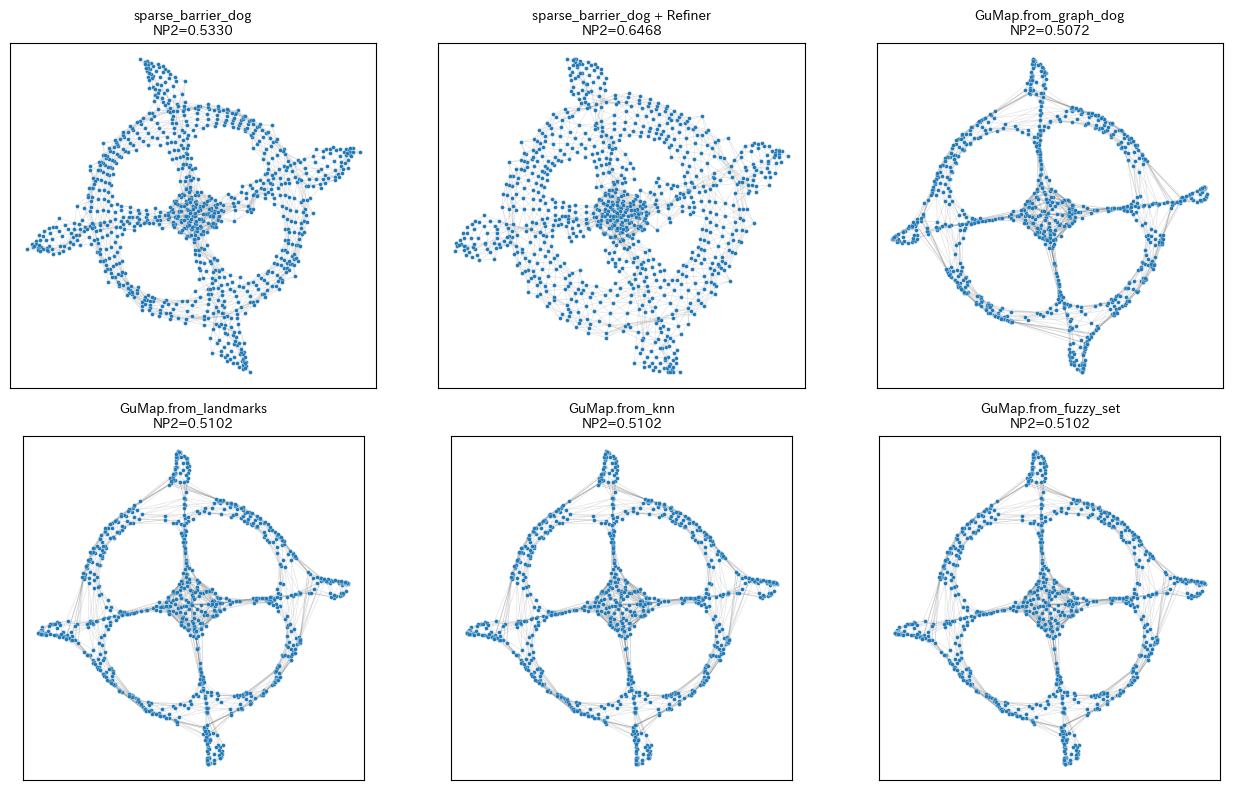

In [ ]:
# 1) SgdSolver.sparse_barrier_dog & sparse_barrier_from_landmarks + SpatialIntruderRefiner on dwt_1005
l_sb_dog = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
t0 = time.perf_counter()
sb_dog = eg.SgdSolver.sparse_barrier_dog(g_dwt, num_landmarks=48, t_max=60, seed=42)
sb_dog.run(l_sb_dog)
dt_sb_dog = (time.perf_counter() - t0) * 1000
print("sparse_barrier_dog stats():", sb_dog.stats())
print("sparse_barrier_dog dog_stats():", sb_dog.dog_stats())

l_sb_ref = eg.Layout2d.from_coords(l_sb_dog.copy_coords())
t0 = time.perf_counter()
eg.SpatialIntruderRefiner(g_dwt, rounds=4, seed=42).run(l_sb_ref)
dt_sb_ref = dt_sb_dog + (time.perf_counter() - t0) * 1000

l_sb_rhgh = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
sb_rhgh = eg.SgdSolver.sparse_barrier_from_landmarks(g_dwt, lm_rhgh, t_max=60, seed=42)
sb_rhgh.run(l_sb_rhgh)
print("sparse_barrier_from_landmarks dog_stats() (expected None):", sb_rhgh.dog_stats())

# 2) GuMapSolver all 4 constructors
gumap_specs = [
    ("GuMap.from_graph_dog", lambda: eg.GuMapSolver.from_graph_dog(g_dwt, n_epochs=150, seed=42)),
    ("GuMap.from_landmarks", lambda: eg.GuMapSolver.from_landmarks(g_dwt, lm_dog, n_epochs=150, seed=42)),
    ("GuMap.from_knn", lambda: eg.GuMapSolver.from_knn(knn_priority, n_epochs=150, seed=42)),
    ("GuMap.from_fuzzy_set", lambda: eg.GuMapSolver.from_fuzzy_set(fuzzy_dwt, n_epochs=150, seed=42)),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
track_b_panels = [("sparse_barrier_dog", l_sb_dog), ("sparse_barrier_dog + Refiner", l_sb_ref)]
gumap_timings = {}
for name, make_solver in gumap_specs:
    lay = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
    t0 = time.perf_counter()
    solver = make_solver()
    solver.run(lay)
    gumap_timings[name] = (lay, (time.perf_counter() - t0) * 1000)
    print(f"{name}: num_edges={solver.num_edges}, ab=({solver.ab[0]:.4f}, {solver.ab[1]:.4f})")
    track_b_panels.append((name, lay))

for ax, (name, lay) in zip(axes.ravel(), track_b_panels):
    np2 = eg.neighborhood_preservation_2hop(g_dwt, lay)
    plot_graph_2d(g_dwt, lay, ax=ax, title=f"{name}\nNP2={np2:.4f}", node_size=8)
plt.tight_layout()
plt.show()

## 5. 統一近傍・力場ソルバ群（`TFdpSolver`, `IbUmapSolver`, `SgdSolver` 系）

- `TFdpSolver`: 引力・斥力分離型の高速力場ソルバ（`__new__` および `from_knn`）。  
  ※ **実践上の注意**: `TFdpSolver` は座標スパンが大きくなりやすいため、中規模グラフで座標が広く拡散する場合は `backend="ibfft"` のグリッドが最大 512×512 まで膨らんで遅くなることがあります。そのような場合は **`backend="barnes_hut"`** を選ぶと数倍〜数十倍高速に動作します。
- `IbUmapSolver`: 座標がコンパクトに保たれるため `backend="ibfft"` が高速に動作します（`__new__`, `from_landmarks`, `from_knn`, `from_fuzzy_set`）。  
  ※ **API 注意点**: `IbUmapSolver.from_knn` は許容誤差引数名が `sigma_tol` である点にご注意ください（`GuMapSolver` 等は `sigma_tolerance`）。また `IbUmapSolver.__new__` の `max_2hop_per_node` デフォルトは `30` です。
- `SgdSolver` 近傍ファミリー: `snap_t_fdp`, `pacmap_graph`, `pacmap_graph_with_landmarks`, `pacmap_graph_with_backbone`, `largevis`, `drgraph`, `graph_cne` (`"infonce"` / `"neg_tsne"`)

In [ ]:
results = []

def run_and_record(name: str, solver_fn, init_layout: eg.Layout2d | None = None):
    lay = init_layout if init_layout is not None else eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
    t0 = time.perf_counter()
    solver = solver_fn()
    solver.run(lay)
    dt = (time.perf_counter() - t0) * 1000
    np2 = eg.neighborhood_preservation_2hop(g_dwt, lay)
    sns = eg.scale_normalized_stress(g_dwt, lay)
    results.append((name, lay, np2, sns, dt))
    return solver, lay

# TFdpSolver (__new__, from_knn(KnnGraph), from_knn(indptr, indices, weights))
s_tfdp, _ = run_and_record("TFdp (barnes_hut)", lambda: eg.TFdpSolver(g_dwt, backend="barnes_hut", total_iterations=150, seed=42))
s_tfdp_k1, _ = run_and_record("TFdp.from_knn(KnnGraph)", lambda: eg.TFdpSolver.from_knn(knn_priority, backend="barnes_hut", total_iterations=150, seed=42))
s_tfdp_k2, _ = run_and_record(
    "TFdp.from_knn(CSR)",
    lambda: eg.TFdpSolver.from_knn(knn_priority.indptr(), knn_priority.indices(), knn_priority.distances(), backend="barnes_hut", total_iterations=150, seed=42),
)
print(f"TFdp: num_edges={s_tfdp.num_edges}, current_rho={s_tfdp.current_rho:.4f}, fft_calls={s_tfdp.total_fft_2d_calls}")

# IbUmapSolver all 4 constructors (backend="ibfft")
degs_u32 = np.array([g_dwt.degree(u) for u in range(g_dwt.num_nodes)], dtype=np.uint32)
s_ibu, _ = run_and_record("IbUmap (ibfft)", lambda: eg.IbUmapSolver(g_dwt, backend="ibfft", n_epochs=150, seed=42))
s_ibu_lm, _ = run_and_record("IbUmap.from_landmarks", lambda: eg.IbUmapSolver.from_landmarks(g_dwt, lm_dog, backend="ibfft", n_epochs=150, seed=42))
s_ibu_knn, _ = run_and_record("IbUmap.from_knn", lambda: eg.IbUmapSolver.from_knn(knn_priority, sigma_tol=1e-5, backend="ibfft", n_epochs=150, seed=42))
s_ibu_fuz, _ = run_and_record("IbUmap.from_fuzzy_set", lambda: eg.IbUmapSolver.from_fuzzy_set(fuzzy_dwt, degrees=degs_u32, backend="ibfft", n_epochs=150, seed=42))
print(
    f"IbUmap: num_edges={s_ibu.num_edges}, a={s_ibu.a:.4f}, b={s_ibu.b:.4f}, "
    f"ab={s_ibu.ab}, rho={s_ibu.current_rho:.2f}, fft_calls={s_ibu.total_fft_2d_calls}"
)

# SgdSolver neighbor / field suite
run_and_record("snap_t_fdp", lambda: eg.SgdSolver.snap_t_fdp(g_dwt, iterations=200, seed=42))
run_and_record("pacmap_graph", lambda: eg.SgdSolver.pacmap_graph(g_dwt, seed=42))
run_and_record("pacmap_with_landmarks", lambda: eg.SgdSolver.pacmap_graph_with_landmarks(g_dwt, lm_dog, seed=42))
run_and_record("largevis", lambda: eg.SgdSolver.largevis(g_dwt, iterations=200, seed=42))
run_and_record("drgraph", lambda: eg.SgdSolver.drgraph(g_dwt, iterations=250, seed=42))
run_and_record("graph_cne (infonce)", lambda: eg.SgdSolver.graph_cne(g_dwt, objective="infonce", iterations=250, seed=42))
run_and_record("graph_cne (neg_tsne)", lambda: eg.SgdSolver.graph_cne(g_dwt, objective="neg_tsne", iterations=250, seed=42))

# pacmap_graph_with_backbone returns (solver, init_layout, backbone_dict)
t0 = time.perf_counter()
bb_solver, bb_layout, bb_dict = eg.SgdSolver.pacmap_graph_with_backbone(g_dwt, seed=42)
bb_solver.run(bb_layout)
dt_bb = (time.perf_counter() - t0) * 1000
results.append((
    "pacmap_with_backbone",
    bb_layout,
    eg.neighborhood_preservation_2hop(g_dwt, bb_layout),
    eg.scale_normalized_stress(g_dwt, bb_layout),
    dt_bb,
))
print("pacmap_graph_with_backbone dict keys:", list(bb_dict.keys()))
print("  backbone stats:", bb_dict["stats"])

TFdp: num_edges=7616, current_rho=0.1000, fft_calls=0


IbUmap: num_edges=25128, a=1.5769, b=0.8951, ab=(1.5769420470850835, 0.8950617810859172), rho=1.00, fft_calls=750


pacmap_graph_with_backbone dict keys: ['fine_layout', 'coarse_layout', 'coarse_graph', 'node_to_coarse', 'coarse_sizes', 'radii', 'stats']
  backbone stats: {'num_fine_nodes': 1005, 'num_coarse_nodes': 14, 'num_coarse_edges': 26, 'louvain_levels': 1, 'mean_cluster_size': 71.78571428571429, 'max_cluster_size': 127, 'median_l_edge': 5.780737123471679, 'max_radius': 3.075363103917337, 'coarse_overlap_pairs_initial': 9, 'coarse_overlap_pairs_final': 0, 'scale_factor_applied': 0.20785680711631666}


## 6. 定量比較とトレードオフの可視化（`dwt_1005`）

ここまでに実行した Track A・Track B・統一近傍ソルバについて、**2-hop 近傍保持率 (NP2)**、**スケール正規化ストレス (SNS)**、**計算時間** を比較し、代表的なレイアウトを並べて確認します。

Method                          NP2      SNS  Time (ms)
--------------------------------------------------------
TsNet pure_2hop (bh)         0.6831   0.0539     1279.9
sparse_barrier + Refiner     0.6468   0.0388      153.9
pacmap_with_backbone         0.6085   0.1405      217.6
pacmap_graph                 0.6068   0.1521      114.4
pacmap_with_landmarks        0.5913   0.3345      236.1
graph_cne (infonce)          0.5852   0.0252      204.9
drgraph                      0.5584   0.0381      199.7
GuMap.from_graph_dog         0.5072   0.0516      495.4
graph_cne (neg_tsne)         0.4728   0.0318      168.8
snap_t_fdp                   0.4692   0.0361       62.5
IbUmap.from_knn              0.4623   0.0353      776.0
IbUmap.from_landmarks        0.4591   0.0367      754.4
IbUmap.from_fuzzy_set        0.4591   0.0367      773.7
IbUmap (ibfft)               0.4585   0.0366      814.7
TFdp.from_knn(KnnGraph)      0.3732   0.2367      216.1
TFdp.from_knn(CSR)           0.3732   0.2367   

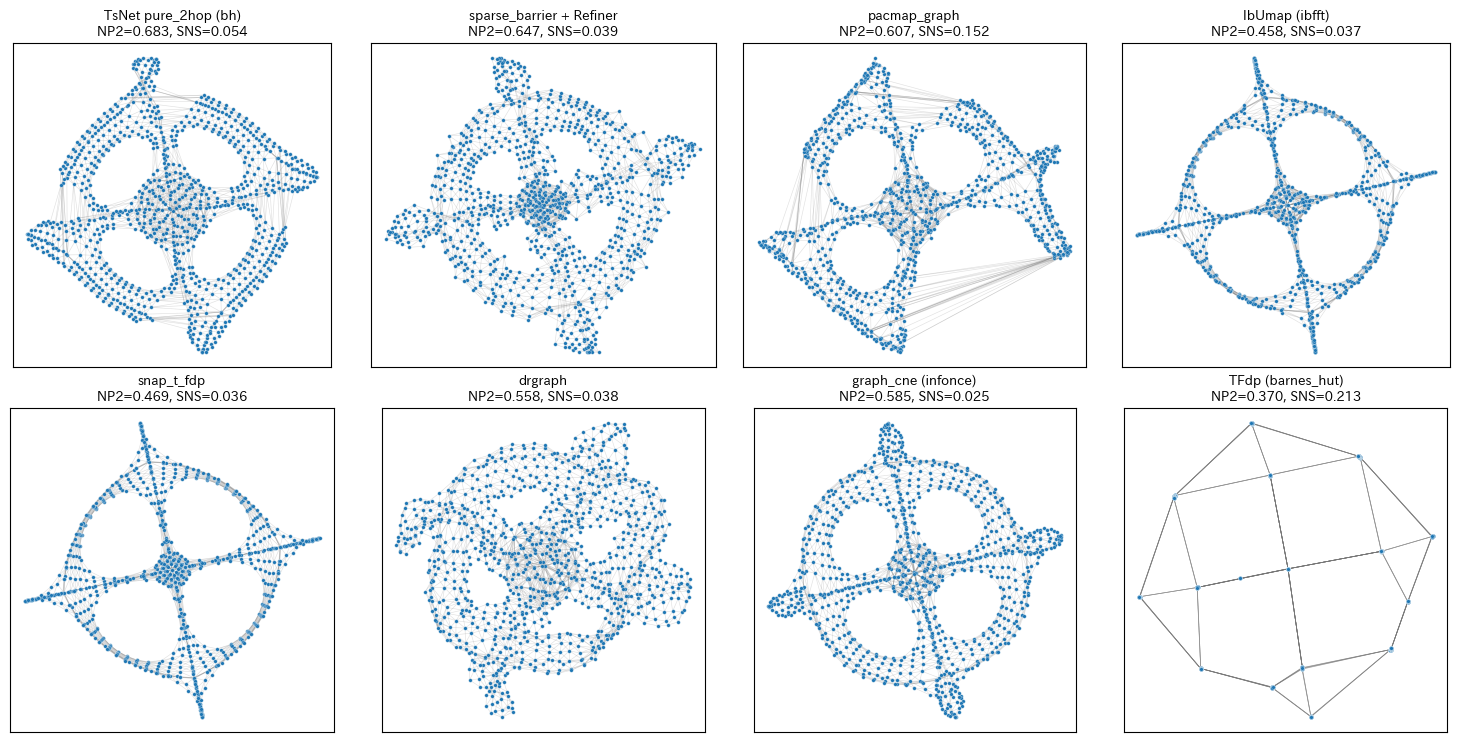

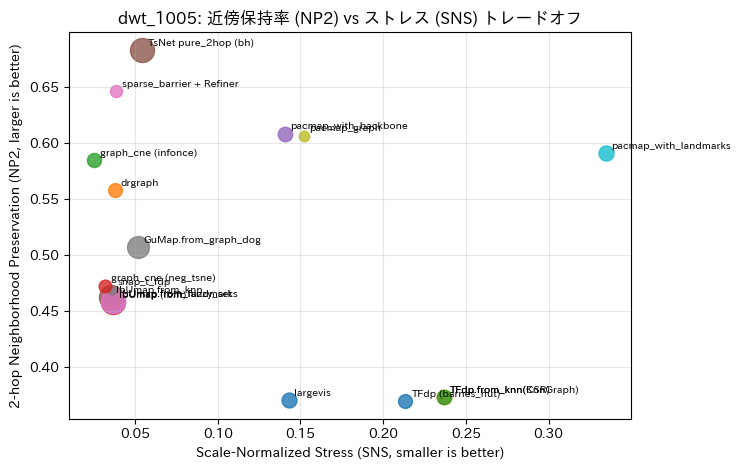

In [ ]:
# Add Track A (TsNetSolver) & Track B (sparse_barrier_dog + Refiner, GuMap) into summary
lay_tsnet = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
t0 = time.perf_counter()
eg.TsNetSolver.pure_2hop(g_dwt, backend="barnes_hut", iterations_stage1=100, iterations_stage2=100, iterations_stage3=200, seed=42).run(lay_tsnet)
dt_ts = (time.perf_counter() - t0) * 1000
results.append(("TsNet pure_2hop (bh)", lay_tsnet, eg.neighborhood_preservation_2hop(g_dwt, lay_tsnet), eg.scale_normalized_stress(g_dwt, lay_tsnet), dt_ts))
results.append(("sparse_barrier + Refiner", l_sb_ref, eg.neighborhood_preservation_2hop(g_dwt, l_sb_ref), eg.scale_normalized_stress(g_dwt, l_sb_ref), dt_sb_ref))
l_gm_dog, dt_gm_dog = gumap_timings["GuMap.from_graph_dog"]
results.append(("GuMap.from_graph_dog", l_gm_dog, eg.neighborhood_preservation_2hop(g_dwt, l_gm_dog), eg.scale_normalized_stress(g_dwt, l_gm_dog), dt_gm_dog))

print(f"{'Method':<26} {'NP2':>8} {'SNS':>8} {'Time (ms)':>10}")
print("-" * 56)
for name, _, np2, sns, dt in sorted(results, key=lambda x: -x[2]):
    print(f"{name:<26} {np2:>8.4f} {sns:>8.4f} {dt:>10.1f}")

# Plot top layouts + NP2 vs SNS trade-off scatter
spotlight_names = [
    "TsNet pure_2hop (bh)",
    "sparse_barrier + Refiner",
    "pacmap_graph",
    "IbUmap (ibfft)",
    "snap_t_fdp",
    "drgraph",
    "graph_cne (infonce)",
    "TFdp (barnes_hut)",
]
res_map = {r[0]: r for r in results}

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, name in zip(axes.ravel(), spotlight_names):
    _, lay, np2, sns, dt = res_map[name]
    plot_graph_2d(g_dwt, lay, ax=ax, title=f"{name}\nNP2={np2:.3f}, SNS={sns:.3f}", node_size=7)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name, _, np2, sns, dt in results:
    ax.scatter(sns, np2, s=max(40, min(300, dt * 0.5)), alpha=0.8)
    ax.annotate(name, (sns, np2), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Scale-Normalized Stress (SNS, smaller is better)")
ax.set_ylabel("2-hop Neighborhood Preservation (NP2, larger is better)")
ax.set_title("dwt_1005: 近傍保持率 (NP2) vs ストレス (SNS) トレードオフ")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()